# NASA Exoplanets: Data Analysis & Habitability Prediction

Project: Exploratory Data Analysis & Modeling

Name: Tina Yaghouti

Goal: Analyze physical and orbital characteristics to predict whether a planet is in the Habitable Zone

## Import Libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set the visual style for plots
sns.set_theme(style="whitegrid", palette="viridis")

## Load & Explore Data

In [10]:
# The file is inside the 'archive' folder
file_path = 'Data/archive/exoplanets_clean.csv'

# Load the dataset
df = pd.read_csv(file_path)

# 1. Display the first 5 rows
print("--- First 5 rows of the dataset ---")
display(df.head())

# 2. Check the shape (Rows and Columns)
print(f"\n--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# 3. Check data types and missing values
print("\n--- Dataset Info ---")
df.info()

# 4. Descriptive statistics for numerical columns
print("\n--- Descriptive Statistics ---")
display(df.describe())

--- First 5 rows of the dataset ---


,pl_name,hostname,discoverymethod,disc_year,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_orbeccen,pl_insol,pl_eqt,st_teff,st_rad,st_mass,st_met,sy_dist,sy_vmag,sy_gaiamag
0,AU Mic b,AU Mic,Transit,2020,8.463080,0.0649,3.956770,87.351625,0.00577,21.20,600.0,3678.0,0.744,0.51,0.23,9.7221,8.810,7.84038
1,AU Mic c,AU Mic,Transit,2021,18.859690,0.1108,2.522021,87.351625,0.00338,7.30,459.0,3678.0,0.744,0.51,0.23,9.7221,8.810,7.84038
2,BD+20 594 b,BD+20 594,Transit,2016,41.685500,0.0688,2.578070,22.248100,0.00000,80.45,939.0,5766.0,1.080,1.67,-0.15,179.4610,10.849,10.86440
3,BD-14 3065 b,BD-14 3065 A,Transit,2024,4.288973,0.0656,21.590000,3932.000000,0.06600,80.45,2001.0,6935.0,2.350,1.41,-0.34,589.4230,11.100,10.91000
4,CoRoT-1 b,CoRoT-1,Transit,2008,1.508956,0.0688,16.700000,327.350000,0.00000,80.45,1898.0,5950.0,1.110,0.95,-0.30,787.9090,13.623,13.45700



--- Dataset Shape ---
Rows: 4473, Columns: 18

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4473 entries, 0 to 4472
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          4473 non-null   object 
 1   hostname         4473 non-null   object 
 2   discoverymethod  4473 non-null   object 
 3   disc_year        4473 non-null   int64  
 4   pl_orbper        4473 non-null   float64
 5   pl_orbsmax       4473 non-null   float64
 6   pl_rade          4473 non-null   float64
 7   pl_bmasse        4473 non-null   float64
 8   pl_orbeccen      4473 non-null   float64
 9   pl_insol         4473 non-null   float64
 10  pl_eqt           4473 non-null   float64
 11  st_teff          4473 non-null   float64
 12  st_rad           4473 non-null   float64
 13  st_mass          4473 non-null   float64
 14  st_met           4473 non-null   float64
 15  sy_dist          4473 non-null   floa

,disc_year,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_orbeccen,pl_insol,pl_eqt,st_teff,st_rad,st_mass,st_met,sy_dist,sy_vmag,sy_gaiamag
count,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000,4473.000000
mean,2017.304047,23.755174,0.092828,4.321183,166.705629,0.051100,142.009565,969.036756,5393.561907,1.008424,0.940274,0.017038,600.460487,13.670737,13.412718
std,3.764254,80.821615,0.132105,4.560723,463.150330,0.082661,385.429282,294.831059,804.135286,0.425843,0.253436,0.147850,466.375569,1.972416,1.912579
min,2002.000000,0.176891,0.006000,0.309800,0.070000,0.000000,0.144000,134.400000,2566.000000,0.012300,0.089800,-0.950000,6.869290,5.650000,5.512800
25%,2014.000000,3.852980,0.067080,1.613000,87.351625,0.033100,80.450000,939.000000,5047.000000,0.770000,0.834000,-0.030000,237.401000,12.415000,12.188200
50%,2016.000000,8.172400,0.068800,2.415000,87.351625,0.033100,80.450000,939.000000,5596.000000,0.933500,0.950000,0.019500,501.574000,13.998500,13.775600
75%,2021.000000,19.446355,0.070600,3.894042,87.351625,0.033100,80.450000,939.000000,5913.000000,1.179000,1.050000,0.070000,862.920000,15.216000,14.954600
max,2026.000000,3650.000000,4.500000,32.600000,8899.195396,0.941200,9110.000000,3646.000000,10000.000000,6.300000,2.780000,0.560000,3460.510000,19.830000,18.886600


In [11]:
# 5. Check the percentage of missing values in key columns
missing_values = df[['pl_rade', 'pl_bmasse', 'pl_eqt']].isnull().mean() * 100
print("--- Percentage of Missing Values in Key Columns ---")
print(missing_values)

--- Percentage of Missing Values in Key Columns ---
pl_rade      0.0
pl_bmasse    0.0
pl_eqt       0.0
dtype: float64


## Data Preparation & Handling Missing Values

Before diving deeper, it is crucial to check for missing values (NaNs). Astronomical datasets often have missing data because not all features can be measured for distant planets
After checking the dataset, we observed that this specific dataset has been pre-cleaned and contains **zero missing values** in our key columns (Radius, Mass, Orbital Period, and Temperature)
Therefore, no imputation or row-dropping is required for our analysis. We can proceed with the clean data

In [13]:
# Verify that there are no missing values in our key columns
missing_check = df[['pl_rade', 'pl_bmasse', 'pl_orbper', 'pl_eqt']].isnull().sum()

print("--- Missing Values Count per Column ---")
print(missing_check)

# Double-check the shape to confirm no data was lost
print(f"\nTotal rows in dataset: {df.shape[0]}")

--- Missing Values Count per Column ---
pl_rade      0
pl_bmasse    0
pl_orbper    0
pl_eqt       0
dtype: int64

Total rows in dataset: 4473


## Outlier Detection

We will use Boxplots to visually identify extreme values in planet radius and mass

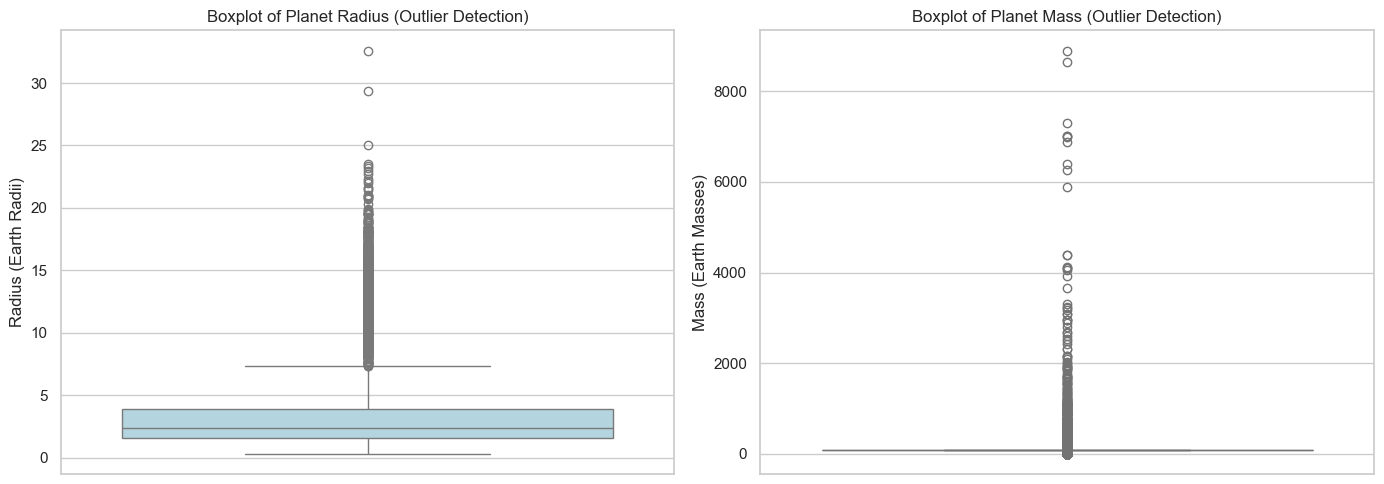

In [14]:
# Boxplots to detect outliers in Radius and Mass
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df['pl_rade'], ax=axes[0], color='lightblue')
axes[0].set_title('Boxplot of Planet Radius (Outlier Detection)')
axes[0].set_ylabel('Radius (Earth Radii)')

sns.boxplot(y=df['pl_bmasse'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of Planet Mass (Outlier Detection)')
axes[1].set_ylabel('Mass (Earth Masses)')

plt.tight_layout()
plt.show()

## Univariate Analysis

In this section, we will explore the distribution of individual variables to understand the dataset better:
- **Planet Radius:** Are most exoplanets Earth-sized or gas giants ?
- **Equilibrium Temperature:** What is the temperature range of the discovered planets ?
- **Discovery Method:** Which method (e.g., Transit) is mostly used to find these planets ?

C:\Users\User\AppData\Local\Temp\ipykernel_14412\1586720555.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='discoverymethod', data=df, ax=axes[2], order=df['discoverymethod'].value_counts().index[:5], palette='magma')


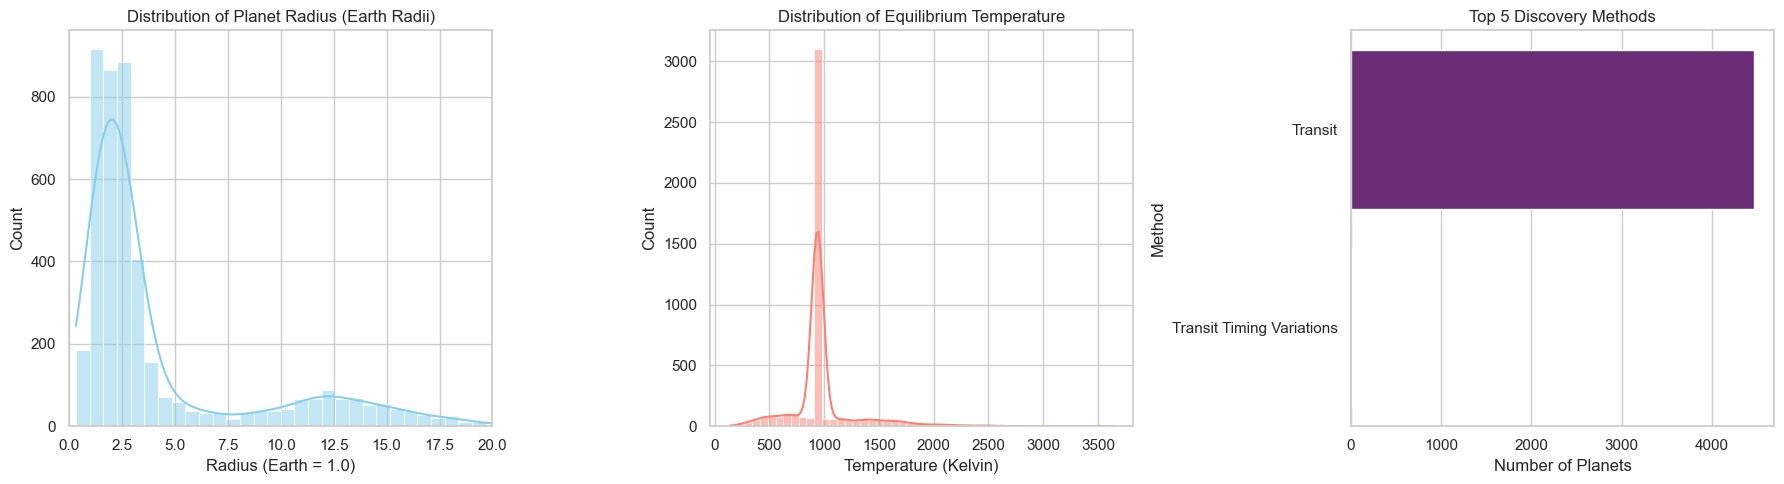

In [7]:
# Create a figure with 3 subplots (1 row, 3 columns) to see them side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram for Planet Radius (pl_rade)
sns.histplot(df['pl_rade'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Planet Radius (Earth Radii)')
axes[0].set_xlabel('Radius (Earth = 1.0)')
axes[0].set_xlim(0, 20) # Limiting X-axis to 20 to zoom in on the majority of planets

# 2. Histogram for Equilibrium Temperature (pl_eqt)
sns.histplot(df['pl_eqt'], bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Equilibrium Temperature')
axes[1].set_xlabel('Temperature (Kelvin)')

# 3. Count Plot for Discovery Method
sns.countplot(y='discoverymethod', data=df, ax=axes[2], order=df['discoverymethod'].value_counts().index[:5], palette='magma')
axes[2].set_title('Top 5 Discovery Methods')
axes[2].set_xlabel('Number of Planets')
axes[2].set_ylabel('Method')

plt.tight_layout()
plt.show()

## Bivariate Analysis

In this section, we will explore the relationships between pairs of variables to answer our primary questions:
- **Orbital Period vs. Temperature:** How does the distance from the host star affect the planet's equilibrium temperature ?
- **Radius vs. Mass:** Is there a strong correlation between the size of a planet and its mass ?

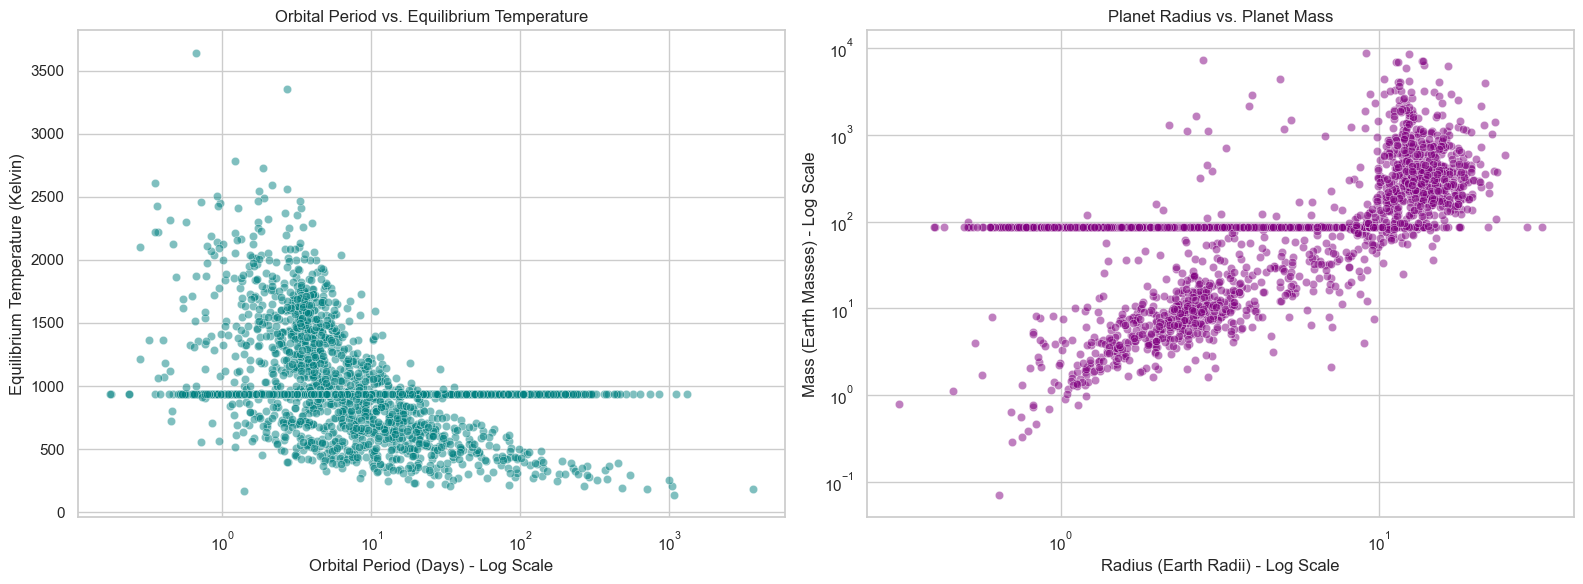

In [8]:
# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatter Plot: Orbital Period vs. Equilibrium Temperature
# Using log scale for X axis because orbital periods vary drastically
sns.scatterplot(data=df, x='pl_orbper', y='pl_eqt', ax=axes[0], alpha=0.5, color='teal')
axes[0].set_xscale('log') 
axes[0].set_title('Orbital Period vs. Equilibrium Temperature')
axes[0].set_xlabel('Orbital Period (Days) - Log Scale')
axes[0].set_ylabel('Equilibrium Temperature (Kelvin)')

# 2. Scatter Plot: Planet Radius vs. Planet Mass
sns.scatterplot(data=df, x='pl_rade', y='pl_bmasse', ax=axes[1], alpha=0.5, color='purple')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Planet Radius vs. Planet Mass')
axes[1].set_xlabel('Radius (Earth Radii) - Log Scale')
axes[1].set_ylabel('Mass (Earth Masses) - Log Scale')

plt.tight_layout()
plt.show()

## Multivariate Analysis

To answer our main question, we will analyze multiple variables simultaneously
First, we will create a new boolean feature called `in_habitable_zone` based on the planet's equilibrium temperature (between 180K and 310K, where liquid water can exist)
Then, we will compare the physical characteristics of planets inside and outside this zone

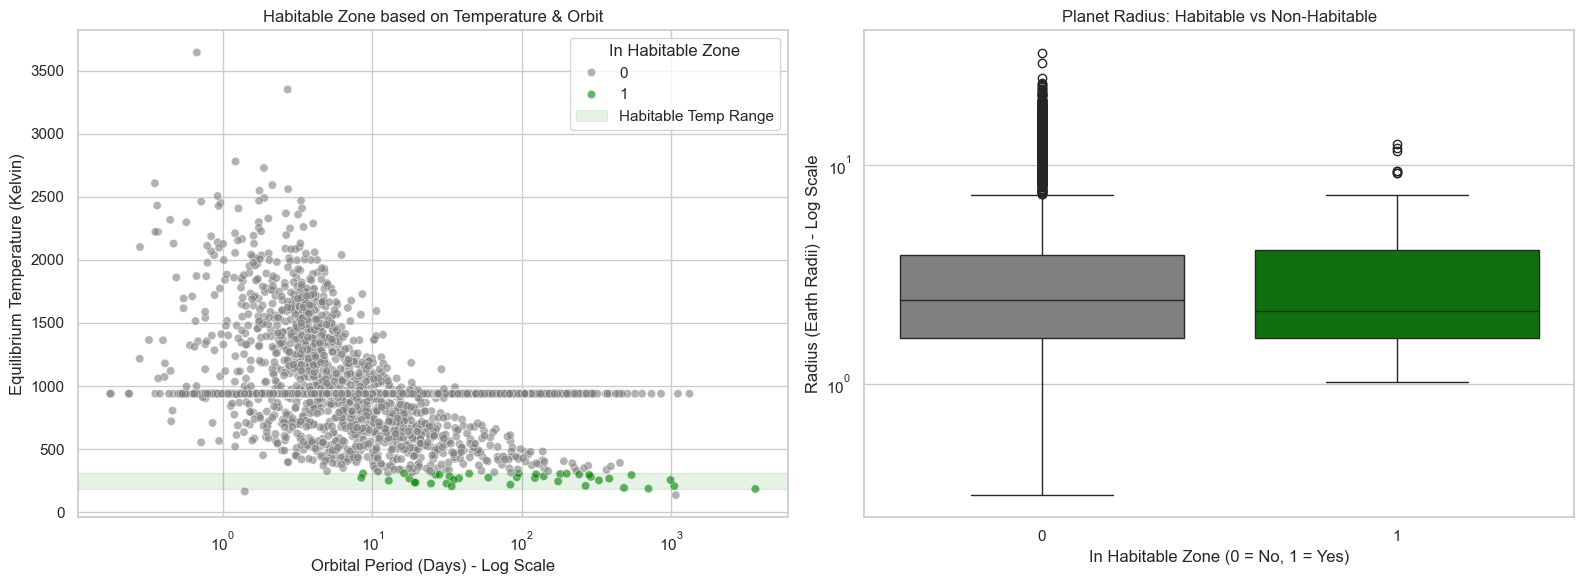

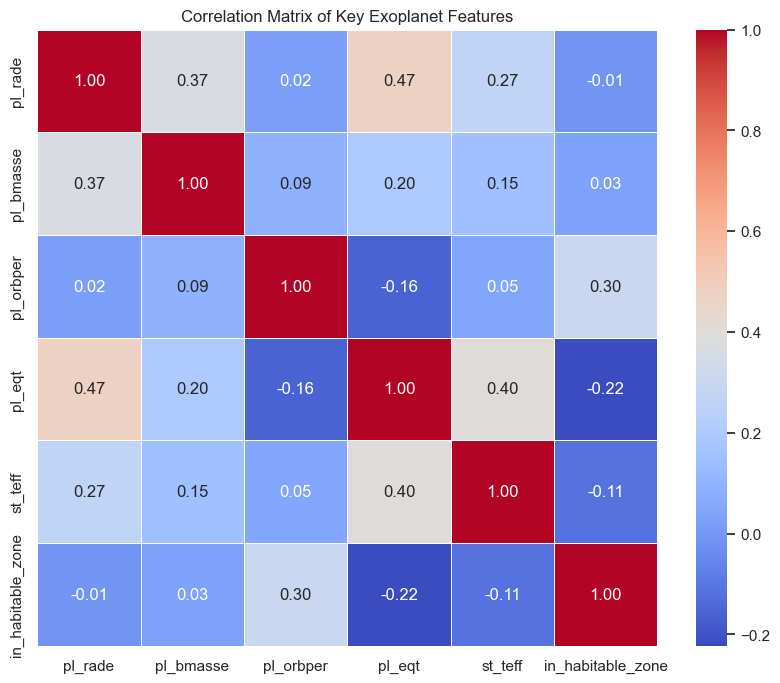

In [9]:
# 1. Create the 'in_habitable_zone' feature based on temperature
# Assuming habitable zone is between 180K and 310K
df['in_habitable_zone'] = df['pl_eqt'].apply(lambda x: 1 if (x >= 180) and (x <= 310) else 0)

# Create a figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 2. Scatter Plot: Orbital Period vs Temperature, colored by Habitability
sns.scatterplot(
    data=df.dropna(subset=['pl_eqt', 'pl_orbper', 'in_habitable_zone']), 
    x='pl_orbper', y='pl_eqt', 
    hue='in_habitable_zone', palette={0: 'grey', 1: 'green'},
    alpha=0.6, ax=axes[0]
)
axes[0].set_xscale('log')
axes[0].set_title('Habitable Zone based on Temperature & Orbit')
axes[0].set_xlabel('Orbital Period (Days) - Log Scale')
axes[0].set_ylabel('Equilibrium Temperature (Kelvin)')
# Add a horizontal band to visually show the habitable temperature range
axes[0].axhspan(180, 310, color='green', alpha=0.1, label='Habitable Temp Range')
axes[0].legend(title='In Habitable Zone')

# 3. Boxplot: Comparing Planet Radius inside vs outside the Habitable Zone
sns.boxplot(
    data=df.dropna(subset=['pl_rade']), 
    x='in_habitable_zone', y='pl_rade', 
    hue='in_habitable_zone', palette={0: 'grey', 1: 'green'}, 
    ax=axes[1], legend=False
)
axes[1].set_yscale('log')
axes[1].set_title('Planet Radius: Habitable vs Non-Habitable')
axes[1].set_xlabel('In Habitable Zone (0 = No, 1 = Yes)')
axes[1].set_ylabel('Radius (Earth Radii) - Log Scale')

plt.tight_layout()
plt.show()

# 4. Correlation Matrix (Heatmap)
# Select only the most important numerical columns to avoid clutter
cols_to_correlate = ['pl_rade', 'pl_bmasse', 'pl_orbper', 'pl_eqt', 'st_teff', 'in_habitable_zone']
plt.figure(figsize=(10, 8))
sns.heatmap(df[cols_to_correlate].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Key Exoplanet Features')
plt.show()

## Evolution of Exoplanet Discoveries

Has our technology improved over time? Let's analyze how the size of discovered planets has changed over the years (`disc_year`), Early discoveries were mostly massive gas giants, but modern telescopes can find much smaller, Earth-sized planets

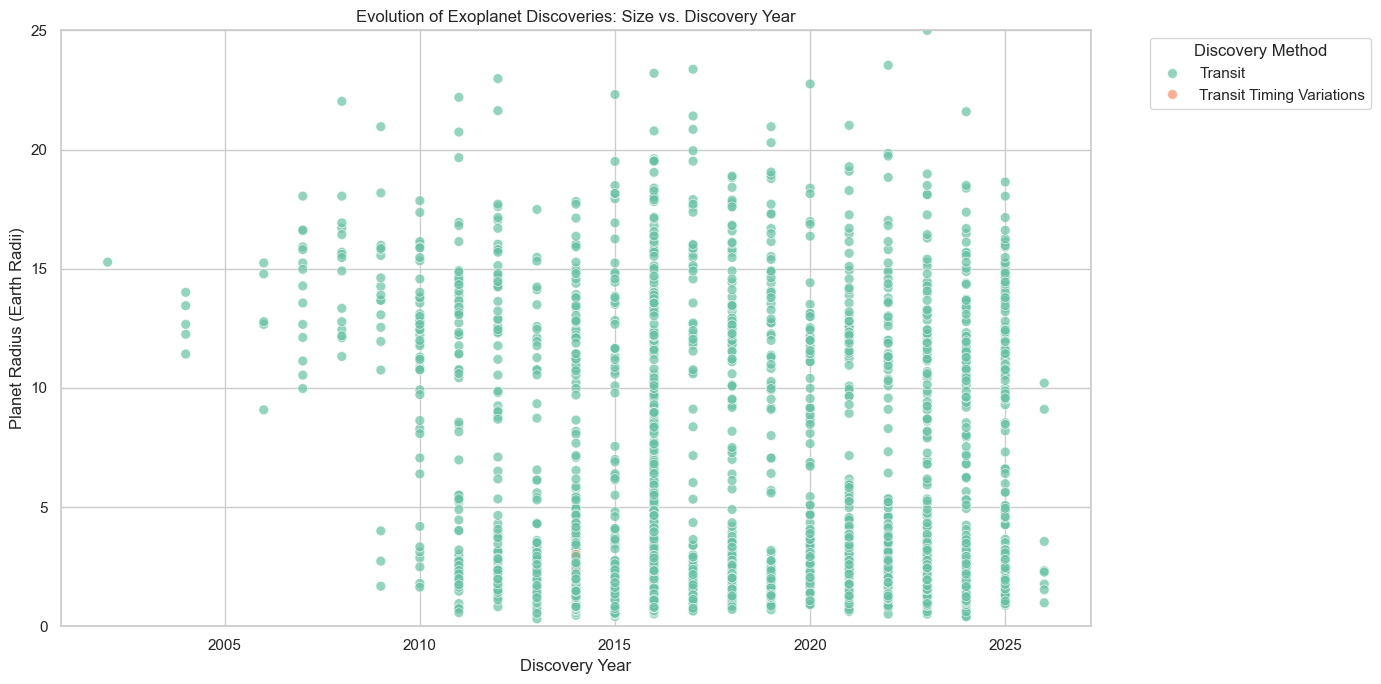

In [15]:
plt.figure(figsize=(14, 7))

# Scatter plot: Discovery Year vs Planet Radius
sns.scatterplot(
    data=df, 
    x='disc_year', 
    y='pl_rade', 
    hue='discoverymethod', 
    alpha=0.7, 
    palette='Set2',
    s=50 # Size of the dots
)

# Limit Y axis to 25 to zoom in on smaller planets (Earth to Neptune size)
plt.ylim(0, 25) 
plt.title('Evolution of Exoplanet Discoveries: Size vs. Discovery Year')
plt.xlabel('Discovery Year')
plt.ylabel('Planet Radius (Earth Radii)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Discovery Method')
plt.tight_layout()
plt.show()

## Conclusion & Insights

Based on the exploratory data analysis of the NASA Exoplanets dataset, we can draw the following conclusions regarding our primary questions:

1. **Distribution of Planets (Univariate):** 
   - The dataset is heavily biased towards planets discovered by the **Transit method**
   - Most discovered exoplanets have a radius larger than Earth (Super-Earths and Mini-Neptunes), Earth-sized planets are actually a minority in current discoveries, which reflects the limitations of our current telescope technology rather than the actual universe

2. **Physical Relationships (Bivariate):**
   - There is a clear negative correlation between **Orbital Period** and **Equilibrium Temperature**. Planets closer to their host star are significantly hotter.
   - A strong positive correlation exists between **Planet Radius** and **Mass**, meaning larger planets are generally heavier

3. **Habitability (Multivariate):**
   - By defining a habitable zone based on temperature (180K - 310K), we observed that planets in this zone tend to have moderate orbital periods
   - Most planets in the habitable zone are relatively small (Earth-sized or slightly larger), making them prime candidates for the search for extraterrestrial life

**Limitations:** 
The dataset contains significant missing values (NaNs), especially in mass and temperature, because measuring these features for distant planets is extremely difficult. Therefore, our analysis is limited to the planets with complete data